
# **MODULE 35.4 — MEL SCALE AND MEL FILTER BANKS**

Must Know

Speech Processing

## **1. Why do we need the Mel scale?**

First, consider two frequencies:

- 500 Hz
- 1,000 Hz

The difference is 500 Hz.

Now consider:

- 5,000 Hz
- 5,500 Hz

The difference is also 500 Hz.

Although both frequency differences are identical, human hearing does not perceive them as equally significant.

Human frequency perception is nonlinear: we are generally more sensitive to frequency differences at lower frequencies than at higher frequencies.

**This is the motivation behind the Mel scale.**

The Mel scale represents frequencies according to a perceptual frequency scale rather than a uniformly spaced Hertz scale.

[Text-to-Speech: Neural Architectures for Natural Speech Synthesis - Interactive | Michael Brenndoerfer](https://images.openai.com/static-rsc-4/PuKCGU_Qv5JdpnOuMNeazg5qkvkhTUh_77j8eMCx8pczIV6xHicsA4ij5eQ_f2rvbuPtHKTQldBxfMWmfE-VN5SZgdFLDE-OKr3sTyfbrU-FI0WkpuYMfzHciLxyeC2Yy8-zKGIScCmERW0UrrOfhtxnvc5zEfhbI1lciLrDvSI?purpose=inline)

[mbrenndoerfer.com](https://mbrenndoerfer.com/writing/text-to-speech-neural-architectures-acoustic-modeling?utm_source=chatgpt.com)

### **Key idea**

| Hertz scale | Mel scale |
|---|---|
| Physical frequency measurement | Perceptual frequency representation |
| Linear frequency spacing | Nonlinear frequency spacing |
| Equal Hz differences have equal spacing | Equal Mel differences represent approximately equal perceptual steps |
| Used in ordinary spectrograms | Used in Mel spectrograms and MFCC extraction |

The Mel scale doesn't change the original audio. It changes how we organize and represent its frequency information.

## **2. Hertz-to-Mel conversion**

Must Know

We need a mathematical relationship to convert frequency in Hertz into Mel units.

A commonly used formula is:

\\[ m = 2595\log_{10}\left(1+\frac{f}{700}\right) \\]

Where:

- \\(m\\) = frequency in Mel.
- \\(f\\) = frequency in Hertz.
- 2595 and 700 = constants used in this Mel-scale approximation.

### **Example: Convert 1,000 Hz into Mel**

\\[ m=2595\log_{10}\left(1+\frac{1000}{700}\right) \\]

\\[ m=2595\log_{10}(2.4286) \\]

\\[ \boxed{m\approx1000\text{ Mel}} \\]

### **Python implementation**

```python
import numpy as np

def hz_to_mel(frequency):
    mel = 2595 * np.log10(1 + frequency / 700)
    return mel

hz_to_mel(1000)
```

The formula is an approximation; different Mel conventions exist.

## **3. Mel-to-Hertz conversion**

We can also convert Mel values back into Hertz.

Starting with:

\\[ m=2595\log_{10}\left(1+\frac{f}{700}\right) \\]

Rearranging:

\\[ \frac{m}{2595}= \log_{10}\left(1+\frac{f}{700}\right) \\]

Taking the inverse logarithm:

\\[ 10^{m/2595}=1+\frac{f}{700} \\]

Therefore:

\\[ \boxed{f=700(10^{m/2595}-1)} \\]

Python:

```python
def mel_to_hz(mel):
    frequency = 700 * (10 ** (mel / 2595) - 1)
    return frequency

mel_to_hz(1000)
```

This approximately returns 1,000 Hz.

### **Visualize the conversion**

```python
import matplotlib.pyplot as plt

frequencies = np.linspace(0, 8000, 500)
mel_values = hz_to_mel(frequencies)

plt.figure(figsize=(10, 5))
plt.plot(frequencies, mel_values)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Frequency (Mel)")
plt.title("Hertz to Mel Conversion")
plt.grid()
plt.show()
```

[【Analytics】Mel Spectrogram explanation - DEV Community](https://dev.to/moyuto/analytics-mel-spectrogram-explanation-4ip7?utm_source=chatgpt.com)

Notice how the curve is nonlinear.

At higher frequencies, the Mel scale compresses the frequency axis.

## **4. What is a Mel filter bank?**

Must Know

Now comes the most important concept.

We have an audio signal, and we can calculate its STFT to obtain a frequency spectrum for every frame.

But instead of treating every FFT frequency bin independently, we group frequency information using a collection of filters.

This collection is called a **Mel filter bank**.

A Mel filter bank contains multiple triangular filters distributed across the frequency spectrum using Mel-scale spacing.

[Speech Representations: From Waveforms to Mel Spectrograms - Interactive | Michael Brenndoerfer](https://mbrenndoerfer.com/writing/speech-representations-mel-spectrograms?utm_source=chatgpt.com)

### **Why triangular filters?**

Each triangular filter:

1. Starts at zero.
2. Gradually increases to a maximum value.
3. Gradually decreases back to zero.

Each filter covers a particular frequency region.

Adjacent filters overlap.

The output of each filter represents the weighted frequency content within its frequency region.

### **Simple illustration**

Imagine a filter bank containing five filters:

```text
Frequency →

Filter 1:     /\
Filter 2:        /\
Filter 3:           /\
Filter 4:              /\
Filter 5:                 /\
```

In a real Mel filter bank, these triangles overlap and are placed according to Mel-frequency spacing.

## **5. How Mel filters are constructed**

Let's understand the actual process.

[spafe.fbanks.mel_fbanks — SuperKogito/Spafe documentation](https://superkogito.github.io/spafe/fbanks/mel_fbanks.html?utm_source=chatgpt.com)

Suppose we have:

- Sampling rate = 16,000 Hz
- FFT size = 512
- Number of Mel filters = 40

### **Step 1 — Calculate the frequency range**

The Nyquist frequency is:

\\[ f_{\max}=\frac{f_s}{2} \\]

\\[ f_{\max}=\frac{16000}{2}=8000\text{ Hz} \\]

Our frequency range is:

\\[ 0 \text{ Hz} \rightarrow 8000 \text{ Hz} \\]

### **Step 2 — Convert the frequency limits into Mel**

\\[ m_{\min}=Mel(0) \\]

\\[ m_{\max}=Mel(8000) \\]

### **Step 3 — Divide the Mel range**

We want 40 Mel filters.

To construct 40 triangles, we need 42 boundary points:

- First point: lower frequency boundary.
- Last point: upper frequency boundary.
- Remaining points: filter boundaries and peaks.

These points are evenly spaced in Mel units.

### **Step 4 — Convert Mel points back to Hertz**

Each Mel point is converted back into Hertz.

This gives us the frequency locations of the filter boundaries and peaks.

### **Step 5 — Construct triangular filters**

Each triangle is constructed using three points:

- Left boundary.
- Centre or peak.
- Right boundary.

The filter rises from zero to one and then falls to zero.

### **Step 6 — Apply filters to the spectrum**

Each filter is multiplied by the frequency spectrum.

The weighted values are summed to produce one output per Mel filter.

This is repeated for every STFT frame.

## **6. Applying Mel filters to a power spectrum**

Must Know

Let's understand the mathematical operation.

Suppose we have a power spectrum:

\\[ P[k]=|X[k]|^2 \\]

Where:

- \\(X[k]\\) = FFT coefficient.
- \\(P[k]\\) = power at frequency bin \\(k\\).

We also have a Mel filter bank matrix:

\\[ M \in \mathbb{R}^{40\times257} \\]

Why 257 frequency bins?

For a real-valued signal with a 512-point FFT, the one-sided spectrum contains:

\\[ \frac{512}{2}+1=257 \\]

frequency bins.

Our filter bank has 40 filters and 257 frequency-bin weights per filter.

Therefore:

\\[ \text{Mel Spectrum}=M\times P \\]

For multiple frames:

\\[ \boxed{S_{\text{Mel}}=M P} \\]

Where:

- \\(M\\) = Mel filter bank matrix.
- \\(P\\) = Power spectrogram.
- \\(S_{\text{Mel}}\\) = Mel spectrogram.

### **Understanding the dimensions**

Suppose our power spectrogram has:

\\[ P\in\mathbb{R}^{257\times401} \\]

And the Mel filter bank has:

\\[ M\in\mathbb{R}^{40\times257} \\]

Then:

\\[ (40\times257)(257\times401) \\]

Result:

\\[ \boxed{S_{\text{Mel}}\in\mathbb{R}^{40\times401}} \\]

We have reduced the frequency dimension from 257 bins to 40 Mel bands.

This is the important transformation.

## **7. Number of Mel bands**

Must Know

How many Mel filters should we use?

Common choices include:

| Mel bands | Typical use |
|---|---|
| 20 | Compact representations |
| 40 | Common speech-processing configuration |
| 64 | Higher-dimensional representation |
| 80 | Widely used in modern speech and audio models |
| 128 | More detailed frequency representation |

There is no universally optimal number.

### **What happens when we change the number?**

**Fewer Mel bands:**

- Lower dimensionality.
- More compression.
- Less frequency detail.

**More Mel bands:**

- More frequency detail.
- Higher dimensionality.
- Potentially more computational cost.

For our SER project, let's begin with:

```python
N_MELS = 40
```

Later, we can experiment with 40, 64, and 80 Mel bands.

The best choice should be determined by validation performance, not assumption.



## **8. What does Mel scaling preserve and compress?**

This is an important conceptual question.

Mel scaling changes the frequency representation by grouping nearby frequency bins into perceptually spaced bands.

### **What it preserves**

- Broad frequency-energy distribution.
- Important spectral patterns across frequency regions.
- Much of the information useful for speech representation.

### **What it compresses**

- Fine-grained frequency resolution.
- Individual distinctions between nearby FFT bins.
- Some detailed spectral information, particularly at higher frequencies.

**Important:** Mel filtering is a many-to-fewer transformation. Once the original frequency bins have been aggregated, we generally cannot reconstruct the exact original spectrum.

This is a form of dimensionality reduction.

## **9. Hertz spectrogram versus Mel spectrogram**

Must Know

Now let's compare the two representations.

**Hertz spectrogram**

Linear frequency representation.

**Mel spectrogram**

Perceptually spaced frequency representation.

| Property | Hertz spectrogram | Mel spectrogram |
|---|---|---|
| Frequency axis | Linear | Mel-scaled |
| Frequency resolution | FFT-bin based | Mel-band based |
| Frequency grouping | Individual bins | Triangular filters |
| Dimensionality | Depends on FFT | Depends on Mel bands |
| Fine spectral details | More available | Some are compressed |
| Common application | Signal analysis | Speech and audio ML |

**Remember:** A Mel spectrogram is not a different kind of audio signal. It is a transformed representation of the original spectrogram.

# **10. Practical implementation — Build a Mel filter bank**

Let's construct one ourselves before using `librosa`.

This will help you understand exactly what the library does internally.

### **Step 1 — Define configuration**

```python
import numpy as np
import matplotlib.pyplot as plt

SR = 16000
N_FFT = 512
N_MELS = 40
FMIN = 0
FMAX = SR // 2
```

### **Step 2 — Create the conversion functions**

```python
def hz_to_mel(frequency):
    return 2595 * np.log10(1 + frequency / 700)

def mel_to_hz(mel):
    return 700 * (10 ** (mel / 2595) - 1)
```

### **Step 3 — Generate equally spaced Mel points**

We need `N_MELS + 2` points.

```python
mel_min = hz_to_mel(FMIN)
mel_max = hz_to_mel(FMAX)

mel_points = np.linspace(
    mel_min,
    mel_max,
    N_MELS + 2
)

hz_points = mel_to_hz(mel_points)
```

### **Step 4 — Convert Hertz points into FFT-bin positions**

For a real-valued signal, the one-sided FFT has 257 bins.

The bin locations are approximately:

\\[ k=\frac{fN_{\text{FFT}}}{f_s} \\]

Python:

```python
fft_bins = np.floor(
    (N_FFT + 1) * hz_points / SR
).astype(int)
```

### **Step 5 — Construct triangular filters**

```python
filter_bank = np.zeros(
    (N_MELS, N_FFT // 2 + 1)
)

for m in range(1, N_MELS + 1):

    left = fft_bins[m - 1]
    center = fft_bins[m]
    right = fft_bins[m + 1]

    # Rising slope
    for k in range(left, center):
        if center != left:
            filter_bank[m - 1, k] = (
                (k - left) / (center - left)
            )

    # Falling slope
    for k in range(center, right):
        if right != center:
            filter_bank[m - 1, k] = (
                (right - k) / (right - center)
            )
```

### **Step 6 — Visualize the Mel filter bank**

```python
frequencies = np.linspace(
    0,
    SR / 2,
    N_FFT // 2 + 1
)

plt.figure(figsize=(14, 6))

for i in range(N_MELS):
    plt.plot(
        frequencies,
        filter_bank[i]
    )

plt.xlabel("Frequency (Hz)")
plt.ylabel("Filter Weight")
plt.title("Triangular Mel Filter Bank")
plt.grid()
plt.show()
```

You should see multiple overlapping triangular filters.

**Implementation note:** This is a simplified educational implementation. Some filters may have degenerate or zero-width bins with small FFT sizes. Production libraries also provide conventions for filter normalization and boundary handling.

# **11. Practical implementation — Generate a Mel spectrogram**

Now let's use `librosa`, which handles the filter-bank construction and application.

### **Step 1 — Load your recording**

```python
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

audio, sr = librosa.load(
    "sample.wav",
    sr=16000,
    mono=True
)
```

### **Step 2 — Calculate the power Mel spectrogram**

```python
mel_spectrogram = librosa.feature.melspectrogram(
    y=audio,
    sr=sr,
    n_fft=512,
    hop_length=160,
    win_length=400,
    n_mels=40,
    fmin=0,
    fmax=8000,
    power=2.0
)

print(mel_spectrogram.shape)
```

The output shape will be:

```python
(40, number_of_frames)
```

The first dimension represents Mel bands.

The second dimension represents time frames.

### **Step 3 — Convert to decibels**

The Mel spectrogram contains power values.

These values can have a large dynamic range, so we commonly convert them into a logarithmic decibel representation.

```python
mel_db = librosa.power_to_db(
    mel_spectrogram,
    ref=np.max
)
```

This produces a log-scaled Mel spectrogram.

### **Step 4 — Visualize it**

```python
plt.figure(figsize=(12, 5))

librosa.display.specshow(
    mel_db,
    sr=sr,
    hop_length=160,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(format="%+2.0f dB")
plt.title("Mel Spectrogram")
plt.tight_layout()
plt.show()
```

# **12. Why Mel representations are commonly used in speech models**

Let's connect everything to your SER project.

A raw waveform contains thousands of samples per second.

An STFT converts it into a time-frequency representation.

A Mel filter bank then compresses the frequency dimension into perceptually spaced bands.

This provides a compact representation that preserves useful broad spectral patterns.

Mel representations are commonly used in:

- Speech Emotion Recognition.
- Automatic Speech Recognition.
- Speech enhancement.
- Audio event classification.
- Text-to-speech systems.

For your project, two important directions are:

| Model approach | Input |
|---|---|
| Classical ML | Statistical features extracted from Mel representations |
| CNN | Mel spectrogram treated as a 2D time-frequency input |

Later, we'll compare these approaches.

## **What you should remember**

1. Human frequency perception is nonlinear, motivating the Mel scale.
2. Hertz-to-Mel conversion transforms the frequency axis.
3. Mel filter banks contain overlapping triangular filters.
4. Mel filters aggregate FFT-bin information into fewer frequency bands.
5. Increasing the number of Mel bands preserves more frequency detail but increases dimensionality.
6. Mel spectrograms are widely useful for speech and audio ML.
7. Mel filtering compresses frequency information; it does not preserve every original FFT detail.

---


In [1]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

audio, sr = librosa.load(
    "audio/raw/sample-speech-1m.mp3",
    sr=16000,
    mono=True
)

In [2]:
mel_spectrogram = librosa.feature.melspectrogram(
    y=audio,
    sr=sr,
    n_fft=512,
    hop_length=160,
    win_length=400,
    n_mels=40,
    fmin=0,
    fmax=8000,
    power=2.0
)

print(mel_spectrogram.shape)

(40, 6001)


In [3]:
mel_db = librosa.power_to_db(
    mel_spectrogram,
    ref=np.max
)

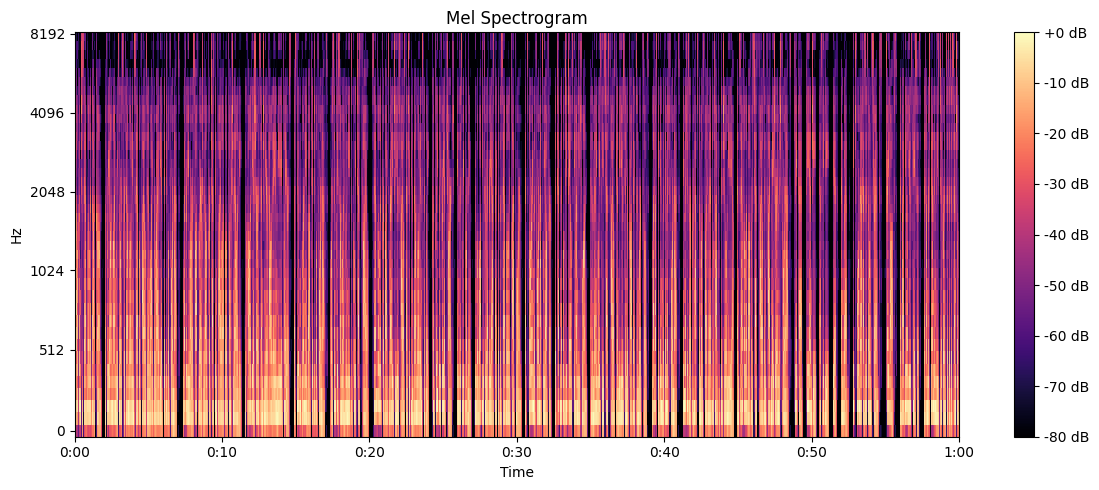

In [4]:
plt.figure(figsize=(12, 5))

librosa.display.specshow(
    mel_db,
    sr=sr,
    hop_length=160,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(format="%+2.0f dB")

plt.title("Mel Spectrogram")

plt.tight_layout()
plt.show()